# 05 — method_comparisons

**Purpose:** Reproduce the manuscript figure panels from already generated numerical tables. This notebook does not fit scCHART or regenerate the simulations. The computational pipelines are in `scripts/`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Work whether launched from the repository root or its notebooks/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").is_dir() and (ROOT.parent / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "results").is_dir(), "Open from scCHART_analysis/ or notebooks/"
FIG_ROOT = ROOT / "figures"
MM = 1 / 25.4
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = 8, 7, 6, 6, 5.5, 5
LW_AX, LW_DATA = 0.5, 1.0
STRUCT, STRUCT_L = "#3A4F8C", "#A9BCD0"
PROG, PROG_L = "#2A9070", "#9FD3C7"
EPI, JAC = "#C0632B", "#8C8C8C"
INK, MUTED, GUIDE = "#1A1A1A", "#555555", "#C8C8C8"
NEUTRAL_L = "#BDBDBD"

def apply_style() -> None:
    """Matplotlib settings of the frozen figures (Arial, 5-8 pt, editable text in SVG/PDF)."""
    import matplotlib._mathtext as mathtext
    mathtext.SHRINK_FACTOR = 0.84            # sub/superscripts of 6 pt text stay >= 5 pt
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"], "font.size": FS_TICK,
        "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold", "mathtext.sf": "Arial", "mathtext.default": "it",
        "axes.labelsize": FS_LABEL, "axes.titlesize": FS_LABEL, "axes.titlepad": 3,
        "axes.linewidth": LW_AX, "axes.edgecolor": INK, "axes.labelcolor": INK, "axes.labelpad": 2,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "xtick.major.width": LW_AX,
        "ytick.major.width": LW_AX, "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5,
        "ytick.major.pad": 1.5, "xtick.color": INK, "ytick.color": INK,
        "legend.fontsize": FS_ANN, "legend.frameon": False, "legend.handletextpad": 0.4,
        "legend.borderaxespad": 0.2, "legend.labelspacing": 0.25,
        "lines.linewidth": LW_DATA, "lines.markersize": 2.6, "errorbar.capsize": 0,
        "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
        "figure.facecolor": "white", "savefig.facecolor": "white",
    })

class Canvas:
    """A figure laid out in millimetres, origin at the top-left corner."""

    def __init__(self, width_mm: float, height_mm: float):
        import matplotlib.pyplot as plt
        self.fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
        # Matplotlib rounds the figure size to whole pixels (183 mm -> 7.2 in); positions are computed from the
        # realised size, as in the frozen figures, so element coordinates match them exactly.
        self.W, self.H = (v / MM for v in self.fig.get_size_inches())

    def ax(self, x, y, w, h, **kw):
        return self.fig.add_axes([x / self.W, 1 - (y + h) / self.H, w / self.W, h / self.H], **kw)

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", FS_ANN); kw.setdefault("va", "top"); kw.setdefault("color", INK)
        return self.fig.text(x / self.W, 1 - y / self.H, s, **kw)

    def letter(self, x, y, s):
        return self.text(x, y, s, fontsize=FS_LETTER, fontweight="bold", ha="left")

    def legend_at(self, handles, x, y, **kw):
        """Figure legend whose top centre is at (x, y) mm."""
        return self.fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x / self.W, 1 - y / self.H),
                               borderaxespad=0, **kw)

class Region:
    """A panel region of a Canvas: the same placement calls, in mm relative to the region's top-left corner."""

    def __init__(self, cv: Canvas, x0: float, y0: float):
        self.cv, self.x0, self.y0, self.fig = cv, x0, y0, cv.fig

    def ax(self, x, y, w, h, **kw):
        return self.cv.ax(self.x0 + x, self.y0 + y, w, h, **kw)

    def text(self, x, y, s, **kw):
        return self.cv.text(self.x0 + x, self.y0 + y, s, **kw)

    def letter(self, s):
        return self.cv.letter(self.x0, self.y0, s)

    def head(self, x, y, s, w=None, color=None, fontsize=None):
        """Bold section heading, optionally underlined by a guide rule of width w mm."""
        self.text(x, y, s, fontsize=fontsize or FS_ANN, fontweight="bold", color=color or INK)
        if w:
            a = self.ax(x, y + 3.4, w, 0.4); a.set_xlim(0, 1); a.set_ylim(0, 1); blank(a)
            a.plot([0, 1], [0.5, 0.5], c=GUIDE, lw=0.5)

def label(ax, s, **kw):
    """Plain left-aligned label above an axes."""
    ax.set_title(s, loc=kw.pop("loc", "left"), fontsize=kw.pop("fontsize", FS_ANN), color=INK, pad=kw.pop("pad", 2), **kw)

def halo(width=1.4):
    import matplotlib.patheffects as pe
    return [pe.withStroke(linewidth=width, foreground="white")]

def fmt_p(p, sym="P"):
    """P = 0.56, P = 0.015, P = 4.7 × 10⁻⁴ (mathtext superscript), as printed on the frozen figures."""
    import numpy as np
    if p >= 0.01:
        s = f"{p:.2f}" if p >= 0.1 else f"{p:#.2g}"
        return f"{sym} = {s}"
    e = int(np.floor(np.log10(p))); m = p / 10 ** e
    if round(m, 1) >= 10:
        m, e = m / 10, e + 1
    return f"{sym} = {m:.1f} × 10$^{{{e}}}$"

def short(g: str) -> str:
    """Granja population id -> display name ('01_HSC' -> 'HSC'; unannotated clusters -> 'Unk 13')."""
    return "Unk " + g.split("_")[0] if g.endswith("Unk") else g.split("_", 1)[1]

def blank(ax) -> None:
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# Manuscript source names -> directories in the public analysis repository.
RESULT_DIRS = {
    "01_synthetic_benchmarks": "01_benchmarks",
    "02_hematopoiesis": "02_granja",
    "03_CATLAS_programmes": "03_catlas",
    "04_xenograft_HSC": "04_hsc",
    "05_method_comparisons": "05_method_comparisons",
}

def result_path(rel):
    parts = Path(rel).parts
    if len(parts) >= 3 and parts[1] == "results":
        return ROOT / "results" / RESULT_DIRS.get(parts[0], parts[0]) / Path(*parts[2:])
    return ROOT / rel

def read(rel, cols=None, n_rows=None):
    path = result_path(rel)
    df = pd.read_csv(path, sep="\t")
    if cols:
        missing = set(cols) - set(df.columns)
        assert not missing, f"{path}: missing {sorted(missing)}"
    if n_rows is not None:
        assert len(df) == n_rows, f"{path}: {len(df)} rows, expected {n_rows}"
    return df

def printed(panel, quantity, exact, fmt, source, flag=False):
    # Format a value read from a result table; no frozen-manuscript comparisons.
    return fmt(exact) if callable(fmt) else (format(exact, fmt) if fmt else str(exact))

OUTPUT_DIR = FIG_ROOT / "02_granja"  # notebook section sets this explicitly.

def save(fig, name):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for ext, opts in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = OUTPUT_DIR / f"{name}.{ext}"
        fig.savefig(path, **opts)
        print(path.relative_to(ROOT))

def build(name, size_mm, panels):
    cv = Canvas(*size_mm)
    for letter, x, y, draw in panels:
        region = Region(cv, x, y)
        draw(region)
        if letter:
            region.letter(letter)
    save(cv.fig, name)
    return cv

fs = SimpleNamespace(**{k: globals()[k] for k in (
    "apply_style", "Canvas", "Region", "label", "halo", "fmt_p", "short", "blank",
    "read", "save", "build", "printed", "ROOT", "STRUCT", "STRUCT_L", "PROG", "PROG_L",
    "EPI", "JAC", "INK", "MUTED", "GUIDE", "NEUTRAL_L", "FS_LETTER", "FS_LABEL",
    "FS_TICK", "FS_ANN", "FS_SMALL", "FS_MIN")})
apply_style()


## Figure 2

**Main Figure 2d–e.** Panel d contrasts response to separation among scCHART, epiCHAOS and 1−Jaccard. Panel e compares Kendall rank reproducibility between donor pairs. Panels 2a–c are produced by notebook 01.

In [2]:
OUTPUT_DIR = ROOT / "figures" / "05_method_comparisons"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, ConnectionPatch
W, H = 183, 152
AX = 34.0
TOP_AXL = [c + 10.5 for c in (0, 45.75, 91.5, 137.25)]
TOP_Y = 32.0
BOT_AXL = [c + 17.0 for c in (0, 61, 122)]
BOT_Y = 100.0
ROW1, ROW2 = 0.0, 79.0
PANEL_REGIONS = {"a": (0, ROW1, 91.5, 77), "b": (91.5, ROW1, 91.5, 77), "c": (0, ROW2, 61, H - ROW2),
                 "d": (61, ROW2, 61, H - ROW2), "e": (122, ROW2, 61, H - ROW2)}
B1 = "01_synthetic_benchmarks/results/"
A_rep = fs.read(B1 + "structural_benchmark_replicates.tsv", ["benchmark", "level", "J_obs"], 260)
A_sum = fs.read(B1 + "structural_benchmark_summary.tsv", ["benchmark", "level", "J_obs_mean", "spearman_rho_level_J_obs"], 13)
A_view = fs.read(B1 + "structural_benchmark_views.tsv", ["benchmark", "level", "axis_state", "axis_orth", "true_state"], 2000)
B_rep = fs.read(B1 + "programme_benchmark_replicates.tsv", ["delta_p", "Delta_P", "median_P"], 100)
B_sum = fs.read(B1 + "programme_benchmark_summary.tsv", ["delta_p", "Delta_P_mean", "median_P_mean"], 5)
C_rep = fs.read(B1 + "mixture_replicates.tsv", ["k", "Delta_S", "Delta_P"], 310)
C_k = fs.read(B1 + "mixture_summary_by_k.tsv", ["score", "k", "mean", "sd"])
C_sel = fs.read(B1 + "mixture_population_selection.tsv", ["population", "selected"])
D_sum = fs.read("05_method_comparisons/results/method_benchmark_summary.tsv", ["benchmark", "method", "truth", "mean", "sd"])
D_key = fs.read("05_method_comparisons/results/method_comparison_key_values.tsv", ["panel", "quantity", "value"])
E_tau = fs.read("05_method_comparisons/results/donor_tau_pairs.tsv", ["estimator", "tau"])
E_ptau = fs.read("03_CATLAS_programmes/results/donor_programme_tau_pairs.tsv", ["estimator", "tau"], 24)
MIX_POPS = [("12_CD14.Mono.2", "CD14.Mono.2", "#E69F00"), ("22_CD4.M", "CD4.M", "#56B4E9"), ("17_B", "B", "#CC79A7"),
            ("25_NK", "NK", "#009E73"), ("09_pDC", "pDC", "#7A1F5C")]
assert sorted(C_sel.population[C_sel.selected]) == sorted(p for p, _, _ in MIX_POPS)
PCOL = ["#2A9070", "#E3B04B", "#8C6BB1"]
E_EST = [("Delta_G", "scCHART structural", STRUCT, E_tau, "05_method_comparisons/results/donor_tau_pairs.tsv"),
         ("Delta_P_catlas_Bheme", "scCHART programme", PROG, E_ptau, "03_CATLAS_programmes/results/donor_programme_tau_pairs.tsv"),
         ("epiCHAOS_het_adj", "epiCHAOS", fs.EPI, E_tau, "05_method_comparisons/results/donor_tau_pairs.tsv"),
         ("jaccard_dissimilarity", "1 − Jaccard", fs.JAC, E_tau, "05_method_comparisons/results/donor_tau_pairs.tsv")]

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [3]:
def arrow_h(cv, x0, y, x1, label=None):
    a = cv.ax(x0, y - 1.5, x1 - x0, 3); a.set_xlim(0, 1); a.set_ylim(0, 1); fs.blank(a)
    a.annotate("", xy=(1, 0.5), xytext=(0, 0.5), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=0.6, mutation_scale=6))
    if label:
        cv.text((x0 + x1) / 2, y - 1.6, label, ha="center", va="bottom", fontsize=FS_SMALL, color=MUTED)

def arrow_v(cv, x, y0, y1):
    a = cv.ax(x - 1.5, y0, 3, y1 - y0); a.set_xlim(0, 1); a.set_ylim(1, 0); fs.blank(a)
    a.annotate("", xy=(0.5, 1), xytext=(0.5, 0), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=0.6, mutation_scale=5))

def title(cv, axl, y, s, color=INK, sub=None):
    cv.text(axl + AX / 2, y, s, ha="center", fontsize=FS_ANN, fontweight="bold", color=color, linespacing=1.15)
    if sub:
        cv.text(axl + AX / 2, y + 3.0, sub, ha="center", fontsize=FS_SMALL, linespacing=1.15)

def inset_cloud(ax, bench, level):
    v = A_view[(A_view.benchmark == bench) & np.isclose(A_view.level, level)]
    if bench == "two_state":
        for state, c in (("A", STRUCT), ("B", "#8FA6D6")):
            w = v[v.true_state == state]; ax.scatter(w.axis_orth, w.axis_state, s=0.45, c=c, lw=0)
        ax.set(xlim=(-0.5, 0.5), ylim=(-1.75, 1.75))
    else:
        ax.scatter(v.axis_orth, v.axis_state, s=0.45, c=STRUCT, lw=0)
        ax.set(xlim=(-0.5, 0.5), ylim=(-0.5, 0.5))
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(GUIDE); s.set_linewidth(0.4)

def pies(cv, xc, y0, dp, caption):
    D, pitch = 5.6, 6.6
    x0 = xc - pitch - D / 2
    for c in range(3):
        a = cv.ax(x0 + c * pitch, y0, D, D)
        w = np.exp(dp * np.eye(3)[c]); w /= w.sum()
        a.pie(w, colors=PCOL, startangle=90, wedgeprops=dict(lw=0.4, ec="white")); a.set_aspect("equal"); fs.blank(a)
        cv.text(x0 + c * pitch + D / 2, y0 + D + 0.3, f"cell {c + 1}", ha="center", fontsize=FS_MIN, color=MUTED)
    cv.text(xc, ROW1 + 0.4, f"δ$_p$ = {dp:g}", ha="center", fontsize=FS_ANN, fontweight="bold")
    cv.text(xc, ROW1 + 3.9, caption, ha="center", fontsize=FS_SMALL, linespacing=1.15)

def scaled_curve(method):
    """Per-level mean and SD of one method at 50:50 separation, scaled to 0 (lowest level) - 1 (highest level)."""
    s = D_sum[(D_sum.benchmark == "F3b separation (minority 50%)") & (D_sum.method == method)].sort_values("truth")
    assert len(s) == 5 and (s.n == 20).all()
    lo, hi = s["mean"].iloc[0], s["mean"].iloc[-1]
    return s.truth.to_numpy(), ((s["mean"] - lo) / (hi - lo)).to_numpy(), (s["sd"] / abs(hi - lo)).to_numpy()

def key_rho(method_col):
    v = D_key[(D_key.panel == "2d") & D_key.quantity.str.contains(f"separation, {method_col}\\)")].value
    assert len(v) == 1, method_col
    return float(v.iloc[0])

### Panel a — Cell-level distributions

In [4]:
def panel_a(cv):
    TH = 9.0
    specs = [(0, "continuous_dispersion", (0.05, 0.8), "h", "Continuous dispersion", "Dispersion, h", [0, 0.4, 0.8],
              (-0.05, 0.85), "continuous dispersion"),
             (1, "two_state", (0.0, 3.0), "δ", "Two balanced states", "Separation of 50:50 states, δ", [0, 1, 2, 3],
              (-0.18, 3.18), "two balanced states")]
    for col, bench, levs, sym, ttl, xl, xt, xlim, key in specs:
        axl = TOP_AXL[col]
        title(cv, axl, ROW1 + 0.4, ttl, sub="500 cells per population")
        ax = cv.ax(axl, TOP_Y, AX, AX); ax.patch.set_alpha(0)
        r, s = A_rep[A_rep.benchmark == bench], A_sum[A_sum.benchmark == bench].sort_values("level")
        jit = (np.random.default_rng(0).random(len(r)) - 0.5) * 0.025 * r.level.max()
        ax.scatter(r.level + jit, r.J_obs, s=1.5, c=STRUCT_L, lw=0, zorder=1)
        ax.plot(s.level, s.J_obs_mean, "-o", c=STRUCT, ms=2.2, lw=1, zorder=2)
        ax.set(xlabel=xl, xticks=xt, xlim=xlim, ylim=(-0.03, 1.08), yticks=[0, 0.5, 1])
        ax.set_ylabel("Structural $J_G^{(S)}$ (bits)")
        src = B1 + "structural_benchmark_summary.tsv / _replicates.tsv"
        rho = printed("a", f"{key}: Spearman rho", float(s.spearman_rho_level_J_obs.iloc[0]), ".2f", src)
        n = printed("a", f"{key}: replicate observations", len(r), "d", src)
        ax.text(0.98, 0.03, f"Spearman correlation:\nρ = {rho}\nReplicate observations:\nn = {n}", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=FS_MIN, linespacing=1.25)
        centres = []
        for lev in levs:
            xc = axl + (lev - xlim[0]) / (xlim[1] - xlim[0]) * AX
            xc = min(max(xc, axl - 3.0), axl + AX + 2.0)
            a = cv.ax(xc - TH / 2, 11.5, TH, TH); inset_cloud(a, bench, lev)
            a.set_title(f"{sym} = {lev:g}", fontsize=FS_SMALL, pad=1.2)
            yv = float(s.loc[np.isclose(s.level, lev), "J_obs_mean"].iloc[0])
            ax.scatter([lev], [yv], s=22, facecolors="none", edgecolors=MUTED, lw=0.6, zorder=3)
            cv.fig.add_artist(ConnectionPatch(xyA=(0.5, 0), coordsA=a.transAxes, xyB=(lev, yv), coordsB=ax.transData,
                                              color=MUTED, lw=0.5, ls=(0, (1.2, 1.2)), shrinkB=2.6, zorder=1))
            centres.append(xc)
        arrow_h(cv, centres[0] + TH / 2 + 1.2, 16.0, centres[1] - TH / 2 - 1.2)

### Panel b — Population-level rankings

In [5]:
def panel_b(cv):
    c1, c2 = TOP_AXL[2] + AX / 2, TOP_AXL[3] + AX / 2
    pies(cv, c1, 9.4, 0.0, "Similar programme mixtures\nacross cells")
    pies(cv, c2, 9.4, 3.0, "Different programmes\ndominate different cells")
    arrow_h(cv, c1 + 11.5, 12.2, c2 - 11.5, "δ$_p$ increases")
    x0, x1 = c1 - 9.6, c2 + 9.6
    br = cv.ax(x0, 17.6, x1 - x0, 1.4); br.set_xlim(0, 1); br.set_ylim(0, 1); fs.blank(br)
    br.plot([0, 0, 1, 1], [1, 0.3, 0.3, 1], c=MUTED, lw=0.5)
    cv.text((x0 + x1) / 2, 19.5, "all cells belong to the same declared population $G$", ha="center", fontsize=FS_SMALL,
            color=MUTED)
    handles = [Line2D([], [], ls="", marker="o", ms=3.0, mfc=c, mec="none", label=f"programme {k + 1}")
               for k, c in enumerate(PCOL)]
    cv.legend_at(handles, (x0 + x1) / 2, 22.3, ncol=3, fontsize=FS_MIN, handletextpad=0.1, columnspacing=0.8)
    jit = (np.random.default_rng(1).random(len(B_rep)) - 0.5) * 0.14
    a1, a2 = cv.ax(TOP_AXL[2], TOP_Y, AX, AX), cv.ax(TOP_AXL[3], TOP_Y, AX, AX)
    a1.scatter(B_rep.delta_p + jit, B_rep.Delta_P, s=1.5, c=PROG_L, lw=0)
    a1.plot(B_sum.delta_p, B_sum.Delta_P_mean, "-o", c=PROG, ms=2.2, lw=1)
    a1.axhline(0, c=GUIDE, lw=0.4)
    a1.set(xlabel="Programme difference, δ$_p$", xticks=[0, 1, 2, 3])
    a1.set_ylabel("Programme $Δ_G^{(P)}$ (bits)")
    a2.scatter(B_rep.delta_p + jit, B_rep.median_P, s=1.5, c=fs.NEUTRAL_L, lw=0)
    a2.plot(B_sum.delta_p, B_sum.median_P_mean, "-o", c=INK, ms=2.2, lw=1)
    a2.set(xlabel="Programme difference, δ$_p$", ylim=(0, 1.05), xticks=[0, 1, 2, 3], yticks=[0, 0.5, 1])
    a2.set_ylabel("Median $\\mathcal{P}_i$")
    title(cv, TOP_AXL[2], 25.2, "Between cells", color=PROG, sub="variation in programme usage across cells")
    title(cv, TOP_AXL[3], 25.2, "Within cells", sub="diversity of programme usage in each cell")

### Panel c — Association or state composition

In [6]:
def panel_c(cv):
    axl, XL = BOT_AXL[0], (0.6, 5.4)
    title(cv, axl, ROW2 + 0.4, "Mixtures of real\nhematopoietic populations")
    handles = [Line2D([], [], ls="", marker="o", ms=2.8, mfc=c, mec="none", label=n) for _, n, c in MIX_POPS]
    cv.legend_at(handles, axl + AX / 2, BOT_Y + AX + 9.6, ncol=5, fontsize=FS_MIN, handletextpad=0.05, columnspacing=0.6)
    rng = np.random.default_rng(7)
    CY, CD = ROW2 + 9.6, 6.4
    for k in range(1, 6):
        xc = axl + (k - XL[0]) / (XL[1] - XL[0]) * AX
        a = cv.ax(xc - CD / 2, CY, CD, CD); a.set_xlim(-1.05, 1.05); a.set_ylim(-1.05, 1.05); fs.blank(a)
        a.set_aspect("equal"); a.add_patch(Circle((0, 0), 1, fc="white", ec=GUIDE, lw=0.5))
        n = 30 // k * k
        rr, th = np.sqrt(rng.random(n)) * 0.84, rng.random(n) * 2 * np.pi
        a.scatter(rr * np.cos(th), rr * np.sin(th), s=0.7, c=np.repeat([c for _, _, c in MIX_POPS[:k]], n // k), lw=0)
        a.set_title(f"k = {k}", fontsize=FS_SMALL, pad=0.8)
        arrow_v(cv, xc, CY + CD + 0.5, BOT_Y - 0.5)
    ax = cv.ax(axl, BOT_Y, AX, AX)
    rng = np.random.default_rng(4)
    for score, c, cl, lab, off in (("Delta_S", STRUCT, STRUCT_L, "Structural", -0.13),
                                   ("Delta_P", PROG, PROG_L, "Programme", 0.13)):
        ax.scatter(C_rep.k + off + (rng.random(len(C_rep)) - 0.5) * 0.16, C_rep[score], s=1.2, c=cl, lw=0, zorder=1)
        k = C_k[C_k.score == score].sort_values("k")
        ax.errorbar(k.k + off, k["mean"], yerr=k["sd"], fmt="-o", c=c, ms=2.2, lw=1, elinewidth=0.6, zorder=2, label=lab)
    ax.set(xlabel="Populations mixed, k", ylabel="Calibrated excess $Δ_G$ (bits)", xticks=[1, 2, 3, 4, 5], xlim=XL,
           yticks=[0, 0.5, 1, 1.5])
    ax.legend(loc="lower right", fontsize=FS_SMALL, handlelength=1.6)

### Panel d — Quantitative comparisons

In [7]:
def panel_d(cv):
    axl = BOT_AXL[1]
    title(cv, axl, ROW2 + 0.4, "Comparison with\nsimilarity-based methods")
    ax = cv.ax(axl, BOT_Y, AX, AX)
    src = "05_method_comparisons/results/method_comparison_key_values.tsv"
    x, y, e = scaled_curve("jaccard_dissimilarity")
    rj = printed("d", "1 - Jaccard: Spearman rho", key_rho("jaccard_dissimilarity"), ".2f", src)
    ax.errorbar(x, y, yerr=e, fmt="--s", c=fs.JAC, ms=3.6, mfc="white", mew=0.7, lw=0.8, elinewidth=0.6, zorder=2,
                label=f"1 − Jaccard\nρ = {rj}")
    x, y, e = scaled_curve("epiCHAOS")
    re_ = printed("d", "epiCHAOS: Spearman rho", key_rho("epiCHAOS"), ".2f", src)
    ax.errorbar(x, y, yerr=e, fmt="-o", c=fs.EPI, ms=2.0, lw=0.9, elinewidth=0.6, zorder=3, label=f"epiCHAOS\nρ = {re_}")
    x, y, e = scaled_curve("structural_e2e")
    rs = printed("d", "scCHART Delta_G: Spearman rho", key_rho("structural_e2e"), ".2f", src)
    ax.errorbar(x, y, yerr=e, fmt="-o", c=STRUCT, ms=2.4, lw=1.1, elinewidth=0.6, zorder=4,
                label=f"scCHART $Δ_G$\nρ = {rs}")
    ax.axhline(0, c=GUIDE, lw=0.4); ax.axhline(1, c=GUIDE, lw=0.4, ls=":")
    ax.set(xlabel="Separation of 50:50 states", ylabel="Scaled response", xticks=[0, 0.25, 0.5, 0.75, 1],
           ylim=(-0.08, 1.15), yticks=[0, 0.5, 1], xlim=(-0.05, 1.05))
    ax.set_xticklabels(["0", "0.25", "0.5", "0.75", "1"])
    h, lab = ax.get_legend_handles_labels()
    ax.legend(h[::-1], lab[::-1], loc="lower right", bbox_to_anchor=(1.03, -0.01), fontsize=FS_MIN, handlelength=1.4,
              borderpad=0.15, labelspacing=0.25, handletextpad=0.3, frameon=True, framealpha=1, edgecolor="none")

### Panel e — Cross-dataset or regulatory comparison

In [8]:
def panel_e(cv):
    axl = BOT_AXL[2]
    title(cv, axl, ROW2 + 0.4, "Agreement of population\nrankings between donors")
    ax = cv.ax(axl, BOT_Y, AX, AX)
    rng = np.random.default_rng(3)
    for i, (est, lab, c, tab, src) in enumerate(E_EST):
        v = tab[tab.estimator == est].tau.to_numpy()
        assert len(v) == 24, (est, len(v))
        m = float(v.mean())
        txt = printed("e", f"mean tau, {lab.replace('−', '-')}", m, ".2f", src)
        ax.scatter(i + (rng.random(len(v)) - 0.5) * 0.42, v, s=2.6, c=c, lw=0, alpha=0.9)
        ax.plot([i - 0.3, i + 0.3], [m, m], c=INK, lw=1)
        ax.text(i, 1.1, txt, ha="center", va="bottom", fontsize=FS_SMALL)
    ax.axhline(0, c=GUIDE, lw=0.4)
    ax.set_xticks(range(4), [e[1] for e in E_EST], fontsize=FS_SMALL, rotation=35, ha="right", rotation_mode="anchor")
    ax.set(ylabel="Kendall τ of population rankings", ylim=(-0.75, 1.3), xlim=(-0.6, 3.6), yticks=[-0.5, 0, 0.5, 1])

In [ ]:
from IPython.display import display, Image

OUTPUT_DIR = ROOT / "figures" / "05_method_comparisons"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for letter, draw in (("d", panel_d), ("e", panel_e)):
    cv = Canvas(W, H)
    draw(cv)

    # Retain the manuscript panel letter.
    idx = 1 if letter == "d" else 2
    cv.letter(BOT_AXL[idx], ROW2, letter)

    # Crop to visible figure content, not the complete manuscript canvas.
    for ext in ("pdf", "svg", "png"):
        cv.fig.savefig(
            OUTPUT_DIR / f"Figure2{letter}.{ext}",
            bbox_inches="tight",
            pad_inches=0.08,
            dpi=600,
        )

    display(Image(filename=str(OUTPUT_DIR / f"Figure2{letter}.png")))
    plt.close(cv.fig)

## Figure S3

**Method comparisons.** Display the synthetic controls, order recovery and Granja comparison against epiCHAOS and Jaccard using the saved comparison tables.

In [10]:
OUTPUT_DIR = ROOT / "figures" / "05_method_comparisons"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
SIZE = (183, 200)
PANELS = {"a": (0, 0, 91, 58), "b": (92, 0, 91, 58), "c": (0, 62, 91, 78), "d": (92, 62, 91, 78), "e": (0, 142, 91, 58),
          "f": (92, 142, 91, 58)}
PANEL_REGIONS = PANELS
PROGENITOR, UNKNOWN = "#2A9070", "#C4C4C4"
R5, R2 = "05_method_comparisons/results/", "02_hematopoiesis/results/"
epi = fs.read(R5 + "method_benchmark_summary.tsv", ["benchmark", "method", "truth", "norm_mean", "norm_sd"])
rec = fs.read(R5 + "method_order_recovery.tsv", ["benchmark", "method", "spearman_rho"])
key5 = fs.read(R5 + "method_comparison_key_values.tsv", ["panel", "quantity", "value"])
gr = fs.read(R2 + "granja_population_sets_summary.tsv", ["population", "Delta_G", "epiCHAOS_het_adj"], 26).set_index("population")
KEEP = [("F1 real cell-type mixture", "Real-cell mixtures"), ("F2 continuous dispersion", "Continuous dispersion"),
        ("F3b separation (minority 10%)", "Separation, 10% minority"), ("F3b separation (minority 50%)", "Separation, 50:50"),
        ("F3 minority substate (sep=0.5)", "Minority fraction, δ = 0.5"), ("F3 minority substate (sep=1)", "Minority fraction, δ = 1"),
        ("F4 multistate complexity", "Equidistant states")]
METH = [("structural", "scCHART structural"), ("structural_e2e", "scCHART structural (e2e LSI)"),
        ("programme", "scCHART programme"), ("epiCHAOS", "epiCHAOS")]
M4 = [("structural", STRUCT, "-o", "white", "scCHART structural $J_G^{(S)}$ (latent; no null)"),
      ("structural_e2e", STRUCT, "--s", None, "scCHART structural $Δ_G$ (end-to-end LSI; calibrated)"),
      ("programme", PROG, "-o", None, "scCHART programme $Δ_G^{(P)}$ (calibrated)"),
      ("epiCHAOS", EPI, "-D", None, "epiCHAOS (count-corrected)")]

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [11]:
def head(P, s):
    P.head(5, 0.4, s)

def curves(P, bench, ttl, xl, xt, legend):
    head(P, ttl)
    ax = P.ax(13, 8, 50, 38)
    for meth, c, lab, sty in (("structural", STRUCT, "scCHART structural", "-o"), ("epiCHAOS", EPI, "epiCHAOS", "-s")):
        d = epi[(epi.benchmark == bench) & (epi.method == meth)].sort_values("truth")
        ax.errorbar(d.truth, d.norm_mean, yerr=d.norm_sd, fmt=sty, c=c, ms=2.2, lw=1, elinewidth=0.6, label=lab)
    ax.axhline(0, c=GUIDE, lw=0.4); ax.set(xlabel=xl, ylabel="Normalized response", xticks=xt)
    if legend:
        ax.legend(fontsize=FS_SMALL, loc="upper left" if "dispersion" in bench else "lower right")

def curves4(P, bench, ttl, xl, xs, xt, legend):
    head(P, ttl)
    ax = P.ax(13, 17, 66, 34)
    for meth, c, sty, mfc, lab in M4:
        d = epi[(epi.benchmark == bench) & (epi.method == meth)].sort_values("truth")
        assert len(d) == (7 if "minority substate" in bench else 5)
        ax.errorbar(xs * d.truth, d.norm_mean, yerr=d.norm_sd, fmt=sty, c=c, mfc=mfc or c, ms=2.2, lw=0.9, elinewidth=0.6,
                    label=lab)
    ax.axhline(0, c=GUIDE, lw=0.4); ax.set(xlabel=xl, ylabel="Normalized response", xticks=xt, ylim=(-0.12, 1.12))
    if legend:
        ax.legend(fontsize=FS_MIN, ncol=2, loc="lower left", bbox_to_anchor=(-0.17, 1.03), borderaxespad=0, handlelength=1.8,
                  columnspacing=0.8, handletextpad=0.4, labelspacing=0.3)

### Panel a — Cell-level distributions

In [12]:
def panel_a(P): curves(P, "F2 continuous dispersion", "Continuous dispersion", "Dispersion, h", [0, 0.4, 0.8], True)

### Panel b — Population-level rankings

In [13]:
def panel_b(P): curves(P, "F4 multistate complexity", "Equidistant multistate benchmark", "Number of equidistant states", [1, 2, 3, 4, 5], True)

### Panel c — Association or state composition

In [14]:
def panel_c(P):
    head(P, "Recovery of the known benchmark order")
    ax = P.ax(36, 8, 34, 38)
    piv = rec.pivot_table(index="benchmark", columns="method", values="spearman_rho").reindex(
        index=[k for k, _ in KEEP], columns=[m for m, _ in METH])
    im = ax.imshow(piv.values, cmap="Greys", vmin=0, vmax=1, aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            if not np.isfinite(v):
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fc="white", ec=GUIDE, lw=0.4, hatch="////"))
                t = printed("c", "real-cell mixtures, structural e2e", "n.e.", "", R5 + "method_order_recovery.tsv (not evaluated)")
                assert (KEEP[i][0], METH[j][0]) == ("F1 real cell-type mixture", "structural_e2e")
                ax.text(j, i, t, ha="center", va="center", fontsize=FS_MIN, color=MUTED, bbox=dict(fc="white", ec="none", pad=0.3))
            else:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=FS_MIN, color="white" if v > 0.6 else INK)
    ax.set_yticks(range(len(KEEP)), [l for _, l in KEEP])
    ax.set_xticks(range(len(METH)), [l for _, l in METH], rotation=40, ha="right", rotation_mode="anchor", fontsize=FS_SMALL)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    cax = P.ax(72, 8, 1.8, 38); cb = P.fig.colorbar(im, cax=cax); cb.outline.set_visible(False)
    cb.set_label("Spearman ρ with true level", fontsize=FS_ANN); cb.ax.tick_params(labelsize=FS_TICK, length=1.5)
    P.text(72, 50, "n.e., not\nevaluated", fontsize=FS_MIN, color=MUTED)

In [15]:
from types import SimpleNamespace
import pandas as pd
from matplotlib.lines import Line2D

# Original Granja population classification from 02_granja.ipynb
STRICT = ["01_HSC", "05_CMP.LMPP", "06_CLP.1", "15_CLP.2", "07_GMP"]
COMMITTED = ["02_Early.Eryth", "04_Early.Baso", "08_GMP.Neut", "16_Pre.B"]
UNANNOTATED = ["13_Unk", "14_Unk", "26_Unk"]
AMBIGUOUS = ["03_Late.Eryth"]

HSPC, MATURE, UNK = "HSPC", "mature", "unannotated"
HSPC_C, MAT_C, UNK_C = "#B0306F", "#4D4D4D", "#BDBDBD"

STYLE = {
    HSPC: dict(fc=HSPC_C, ec=HSPC_C, m="o", lab="HSPCs", map=HSPC_C),
    MATURE: dict(fc="white", ec=MAT_C, m="o", lab="Mature", map="#8A8A8A"),
    UNK: dict(fc=UNK_C, ec="#8F8F8F", m="s", lab="Unannotated", map="#D9D9D9"),
}

def classify(populations) -> pd.Series:
    s = pd.Series(MATURE, index=list(populations))
    s[s.index.isin(STRICT + COMMITTED)] = HSPC
    s[s.index.isin(UNANNOTATED)] = UNK
    assert (s == HSPC).sum() == 9
    assert (s == MATURE).sum() == 14
    assert (s == UNK).sum() == 3
    return s

def handles(classes: pd.Series, counts=True, keys=(HSPC, MATURE, UNK)):
    n = classes.value_counts()
    return [
        Line2D(
            [], [], ls="", marker=STYLE[k]["m"], ms=3.2,
            mfc=STYLE[k]["fc"], mec=STYLE[k]["ec"], mew=0.6,
            label=f"{STYLE[k]['lab']} ({n[k]})" if counts else STYLE[k]["lab"]
        )
        for k in keys
    ]

gc = SimpleNamespace(
    STRICT=STRICT, COMMITTED=COMMITTED,
    UNANNOTATED=UNANNOTATED, AMBIGUOUS=AMBIGUOUS,
    HSPC=HSPC, MATURE=MATURE, UNK=UNK,
    HSPC_C=HSPC_C, MAT_C=MAT_C, UNK_C=UNK_C,
    STYLE=STYLE, classify=classify, handles=handles
)

### Panel d — Quantitative comparisons

In [16]:
def panel_d(P):
    head(P, "Ranking of 26 Granja populations")
    rs, re_ = gr.Delta_G.rank(ascending=False), gr.epiCHAOS_het_adj.rank(ascending=False)
    cls = gc.classify(gr.index)
    n = cls.value_counts()
    n_h = printed("d", "legend: progenitor/precursor", int(n[gc.HSPC]), "d", "granja_classes.py")
    n_m = printed("d", "legend: mature", int(n[gc.MATURE]), "d", "granja_classes.py")
    n_u = printed("d", "legend: unannotated", int(n[gc.UNK]), "d", "granja_classes.py")
    sty = {gc.HSPC: dict(c=PROGENITOR, mfc=PROGENITOR, m="o", ls="-", lw=0.9, z=3, lab=f"Progenitor/precursor ({n_h})"),
           gc.MATURE: dict(c="#6E6E6E", mfc="white", m="o", ls="-", lw=0.6, z=2, lab=f"Mature ({n_m})"),
           gc.UNK: dict(c="#A8A8A8", mfc=UNKNOWN, m="s", ls=(0, (2, 1.2)), lw=0.6, z=1, lab=f"Unannotated ({n_u})")}
    ax = P.ax(30, 13, 30, 50)
    name = lambda p: (p.split("_", 1)[1] + " " + p.split("_", 1)[0]) if p.endswith("Unk") else p.split("_", 1)[1]
    for p in gr.index:
        st = sty[cls[p]]
        ax.plot([0, 1], [rs[p], re_[p]], c=st["c"], lw=st["lw"], ls=st["ls"], zorder=st["z"])
        for x, r in ((0, rs[p]), (1, re_[p])):
            ax.plot([x], [r], marker=st["m"], ms=2.6, mfc=st["mfc"], mec=st["c"], mew=0.6, zorder=st["z"] + 1, ls="")
        col = PROGENITOR if cls[p] == gc.HSPC else INK
        ax.text(-0.06, rs[p], name(p), ha="right", va="center", fontsize=FS_MIN, color=col)
        ax.text(1.06, re_[p], name(p), ha="left", va="center", fontsize=FS_MIN, color=col)
    ax.set_ylim(26.6, 0.4); ax.set_xlim(-0.02, 1.02); fs.blank(ax)
    ax.text(0, 0.0, "scCHART\nstructural Δ", ha="center", va="bottom", fontsize=FS_SMALL, fontweight="bold", color=STRUCT)
    ax.text(1, 0.0, "epiCHAOS", ha="center", va="bottom", fontsize=FS_SMALL, fontweight="bold", color=EPI)
    v = key5.loc[key5.panel == "S3d", "value"]; assert len(v) == 1
    rho = printed("d", "Spearman Delta_G vs epiCHAOS", float(v.iloc[0]), ".2f", R5 + "method_comparison_key_values.tsv")
    nn = printed("d", "n populations", len(gr), "d", R2 + "granja_population_sets_summary.tsv")
    ax.text(0.5, 27.4, f"Rank 1 = most heterogeneous (top)\nSpearman ρ = {rho}, n = {nn}", ha="center", va="top",
            fontsize=FS_SMALL)
    h = [Line2D([], [], c=v_["c"], lw=v_["lw"], ls=v_["ls"], marker=v_["m"], ms=2.6, mfc=v_["mfc"], mec=v_["c"], label=v_["lab"])
         for v_ in sty.values()]
    P.fig.legend(handles=h, loc="upper left", ncol=3, fontsize=FS_MIN, handlelength=1.6, handletextpad=0.3, columnspacing=0.8,
                 bbox_to_anchor=((P.x0 + 5) / P.cv.W, 1 - (P.y0 + 4.6) / P.cv.H), borderaxespad=0)

### Panel e — Cross-dataset or regulatory comparison

In [17]:
def panel_e(P): curves4(P, "F3 minority substate (sep=1)", "Minority-state abundance (maximal separation)",
                        "Minority state (% of cells)", 100, [0, 10, 20, 30, 40, 50], True)

### Panel f — Within-state analysis

In [18]:
def panel_f(P): curves4(P, "F3b separation (minority 10%)", "State separation with a 10% minority state", "State separation", 1,
                        [0, 0.25, 0.5, 0.75, 1], False)

### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

figures/05_method_comparisons/FigureS3.pdf
figures/05_method_comparisons/FigureS3.svg
figures/05_method_comparisons/FigureS3.png


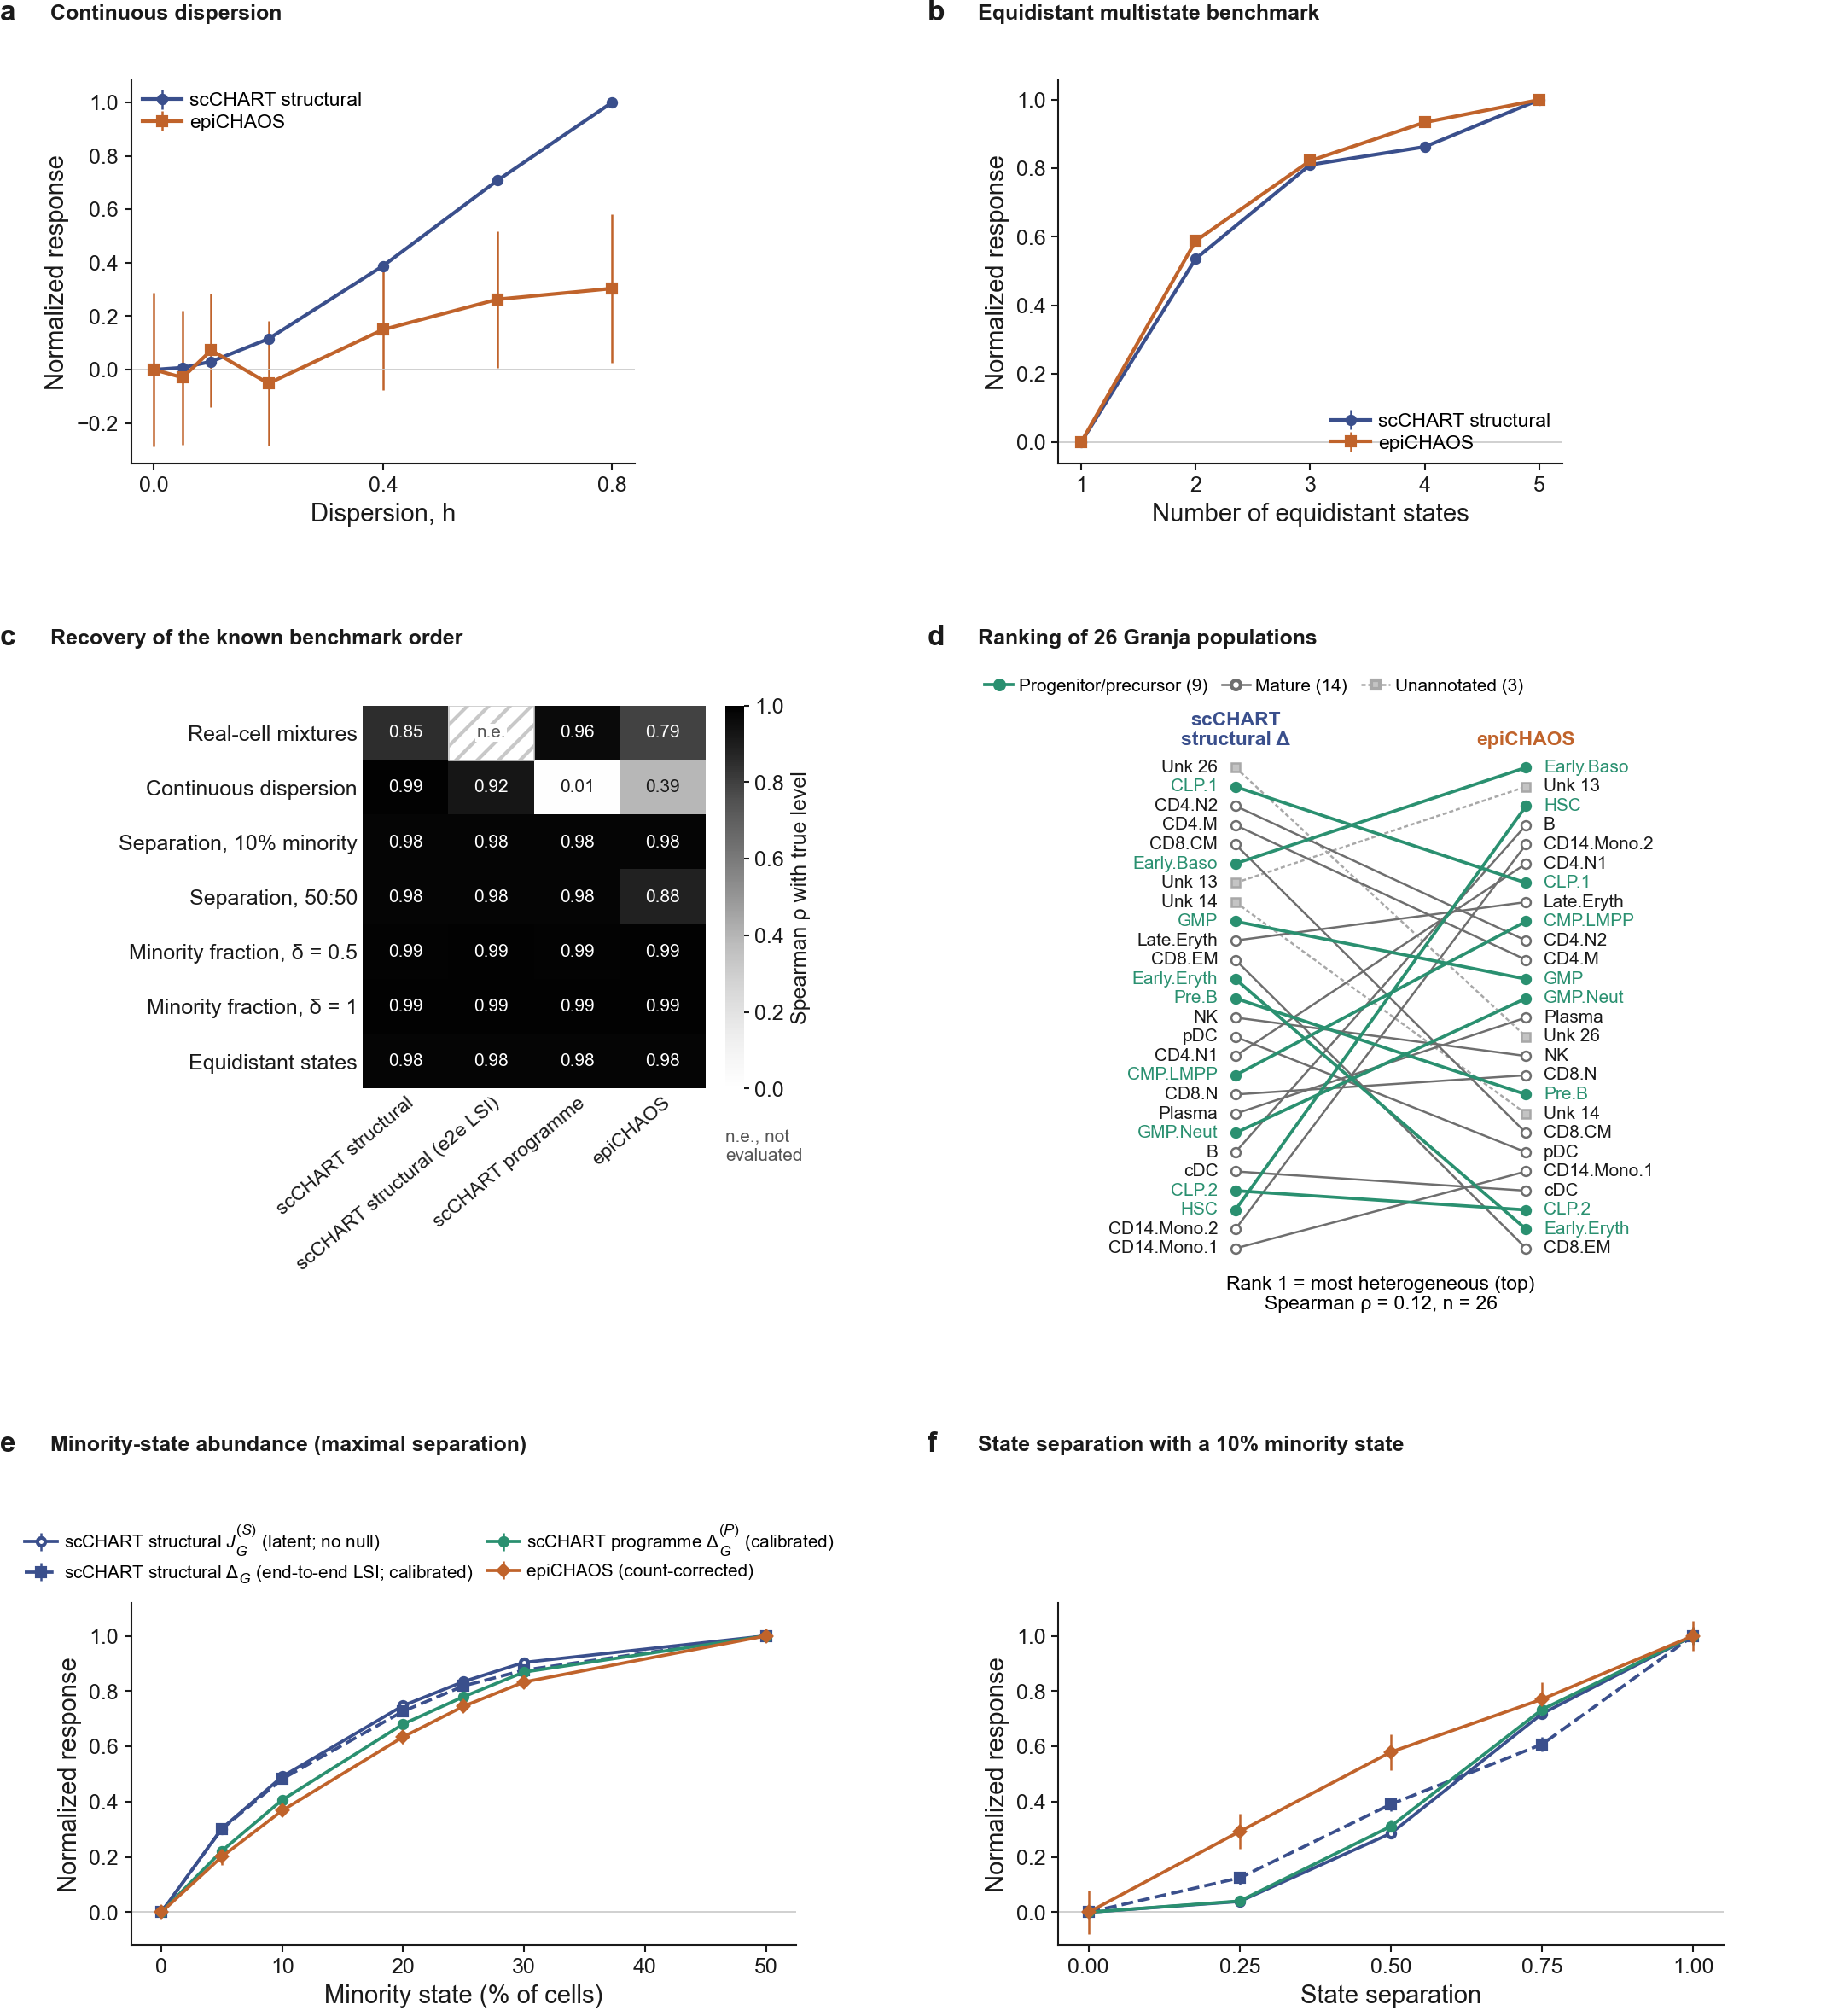

In [19]:
from IPython.display import display, Image
cv = build("FigureS3", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c),('d',PANELS['d'][0],PANELS['d'][1],panel_d),('e',PANELS['e'][0],PANELS['e'][1],panel_e),('f',PANELS['f'][0],PANELS['f'][1],panel_f)])
display(Image(filename=str(OUTPUT_DIR / "FigureS3.png")))
plt.close(cv.fig)